# Основы глубинного обучения, майнор ИАД

## Домашнее задание 1: полносвязные сети

**ФИО:** Телешева Дарья Леонидовна

**Факт о себе:** каждое лето купаюсь в священном байкале


## Общая информация

__Дата выдачи:__ 28.09.2026

__Мягкий дедлайн:__ 23:59MSK 18.10.2026

__Жесткий дедлайн:__ 23:59MSK 25.10.2026


## Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).  Если два студента сгенерировали в нейронке одинаковые либо похожие решения, это считается плагиатом и приводит к обнулению обеих работ.

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Итогова оценка считается как

$$
min(part_1, part_2) \cdot 0.6 + max(part_1, part_2) \cdot 0.2 + part_3 \cdot 0.2
$$

где $part_1$, $part_2$ и $part_3$ - оценки за первую, вторую и третью части работы

> Также, за домашнее задание выставляется 0, если не сделано нулевое задание либо нет подробного описания ваших экспериментов в третьей части.

## Оформление

1. Обязательно фиксируйте зерно генератора случайных чисел в экспериментах. При перезапуске кода значения не должны меняться.
2. Вверху файла подпишите фамилию, имя и какой-то занимательный факт о себе.
3. Обратите внимание, что у графиков должны быть подписаны оси, заголовок графика и при необходимости обязательно наличие легенды.

> За отсутствие названий графиков и подписей к осям могут снижаться баллы. Все картинки должны быть самодостаточны и визуально удобны для восприятия, так чтобы не нужно было смотреть ваш код или знать задание, чтобы понять что на них изображено.

Из каждого проведённого эксперимента делайте выводы и фиксируйте их. Эти выводы не должны быть поверхностными и очевидными. Не будьте мудрым королём.

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/king.png" width="300">
</center>

**Пример плохого вывода:** Синенькая линия идет вверх, а красная вниз. Черненькая идет вниз, а потом вверх.

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/bad_lines.png" width="600">
</center>

## О задании

Вам предстоит обучить полносвязную нейронную сеть для предсказания года выпуска песни по ее аудио-признакам. Для этого мы будем использовать [Million Songs Dataset](https://samyzaf.com/ML/song_year/song_year.html).

In [1]:
import torch
from torch import nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import random

from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

Начнем с того, что скачаем и загрузим данные:

In [2]:
!wget -O yearpredictionmsd.zip https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip

--2026-10-17 17:16:02--  https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘yearpredictionmsd.zip’

yearpredictionmsd.z     [ <=>                ] 201.24M  17.7MB/s    in 94s     

2026-10-17 17:17:38 (2.15 MB/s) - ‘yearpredictionmsd.zip’ saved [211011981]



In [3]:
df = pd.read_csv('yearpredictionmsd.zip', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Посмотрим на статистики по данным.

In [4]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
count,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,...,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000
mean,1998.397082,43.387126,1.289554,8.658347,1.164124,-6.553601,-9.521975,-2.391089,-1.793236,3.727876,...,15.755406,-73.461500,41.542422,37.934119,0.315751,17.669213,-26.315336,4.458641,20.035136,1.329105
std,10.931046,6.067558,51.580351,35.268585,16.322790,22.860785,12.857751,14.571873,7.963827,10.582861,...,32.099635,175.618889,122.228799,95.050631,16.161764,114.427905,173.977336,13.346557,185.558247,22.088576
min,1922.000000,1.749000,-337.092500,-301.005060,-154.183580,-181.953370,-81.794290,-188.214000,-72.503850,-126.479040,...,-437.722030,-4402.376440,-1810.689190,-3098.350310,-341.789120,-3168.924570,-4319.992320,-236.039260,-7458.378150,-381.424430
25%,1994.000000,39.954690,-26.059520,-11.462710,-8.487500,-20.666450,-18.440990,-10.780600,-6.468420,-2.293660,...,-1.812650,-139.555160,-20.986900,-4.669540,-6.781590,-31.580610,-101.530300,-2.566090,-59.509270,-8.820210
50%,2002.000000,44.258500,8.417850,10.476320,-0.652840,-6.007770,-11.188390,-2.046670,-1.736450,3.822310,...,9.171850,-53.090060,28.791060,33.623630,0.820840,15.598470,-21.204120,3.117640,7.759730,0.053050
75%,2006.000000,47.833890,36.124010,29.764820,8.787540,7.741870,-2.388960,6.508580,2.913450,9.961820,...,26.274480,13.478730,89.661770,77.785800,8.470990,67.794960,52.389330,9.967740,86.351610,9.679520
max,2011.000000,61.970140,384.065730,322.851430,335.771820,262.068870,166.236890,172.402680,126.741270,146.297950,...,840.973380,4469.454870,3210.701700,1734.079690,260.544900,3662.065650,2833.608950,463.419500,7393.398440,677.899630


Целевая переменная, год выпуска песни, записана в первом столбце. Посмотрим на ее распределение.

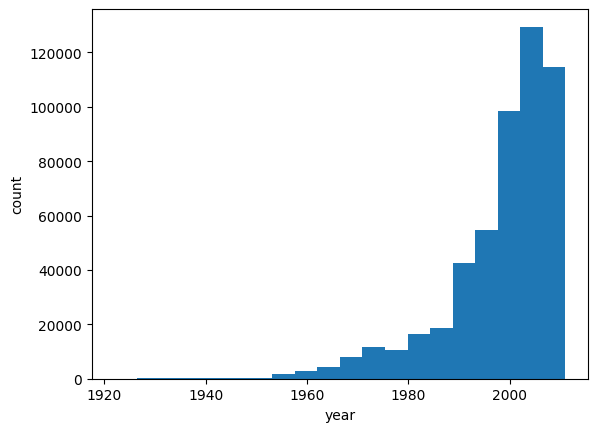

Range: 1922 - 2011
Unique values: 89


In [5]:
plt.hist(df.iloc[:, 0], bins=20)
plt.xlabel('year')
plt.ylabel('count')
plt.show()
print(f'Range: {df.iloc[:, 0].min()} - {df.iloc[:, 0].max()}')
print(f'Unique values: {np.unique(df.iloc[:, 0]).size}')

Разобьем данные на обучение и тест (не меняйте здесь ничего, чтобы сплит был одинаковым у всех).

In [6]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

train_size = int(0.75 * X.shape[0])

X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]

X_train.shape, X_test.shape

((386508, 90), (128837, 90))

## Полезные советы:

- Если вы сразу реализуете обучение на GPU, то у вас будет больше времени на эксперименты, так как любые вычисления будут работать быстрее. Google Colab предоставляет несколько GPU-часов (обычно около 8-10) в сутки бесплатно.

- Если вы чего-то не знаете, не стесняйтесь гуглить. В интернете очень много полезной информации, туториалов и советов по глубинному обучению и `pytorch`. Но не забывайте, что за списанный код без ссылки на источник последует наказание.

- Чтобы отладить код, можете обучаться на небольшой части данных или даже на одном батче. Если лосс на обучающей выборке не падает, то что-то точно идет не так.

- Пользуйтесь утилитами, которые вам предоставляет `pytorch` (например, `Dataset` и `Dataloader`). Их специально разработали для упрощения разработки пайплайна обучения.

- Скорее всего, вы захотите отслеживать прогресс обучения. Для создания прогресс-баров есть удобная библиотека `tqdm`.

- Быть может, вы захотите, чтобы графики рисовались прямо во время обучения. Можете воспользоваться функцией [clear_output](http://ipython.org/ipython-doc/dev/api/generated/IPython.display.html#IPython.display.clear_output), чтобы удалять старый график и рисовать новый на его месте.

- При желании вы можете логгировать метрики обучения и свои эксперименты в WandB либо любой другой сервис. Не забудьте приложить к тетрадке ссылку на результаты экспериментов либо скришноты графиков с пояснениями, что проверяющий должен на них увидеть.

- Финальное значение тестовой метрики для удобства проверки выведите в тетрадке.

## Задание 0 (0 баллов, но при невыполнении максимальная оценка за всю работу &mdash; 0 баллов)

Мы будем использовать RMSE как метрику качества. Прежде чем обучать нейронные сети, нам нужно проверить несколько простых бейзлайнов, чтобы было с чем сравнить более сложные алгоритмы. Для этого бучите `Ridge` регрессию из `sklearn`. Кроме того, посчитайте качество при наилучшем константном прогнозе.

Для выполнения данного задания (и всех последующих) предобработайте данные.

1. Зафиксируйте random_seed везде где только возможно. Вам предоставлена функция для этого, однако вы можете дополнить ее своими дополнениями.
2. Обучите `StandertScaler` и предобработайте ваши данные. В следующих заданиях можете использовать другой `scaler` или вообще отказаться от него.


Берем готовый код из семинара 1

In [7]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    torch.backends.cudnn.deterministic = True
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)

    # также можно зафиксировать seed для Dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    return g

# Сид для каждого worker в Dataloader
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = set_global_seed(42)

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
scaler = StandardScaler()
 # your code here  ⟅⎛ꌩωꌩ⎞⟆
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
 # your code here  ⟅⎛ꌩωꌩ⎞⟆
model = Ridge()
model.fit(X_train_scaled, y_train)
rmse_for_model = np.sqrt(mean_squared_error(y_test, model.predict(X_test_scaled)))
print(f'RMSE Ridge на тесте: {rmse_for_model:.2f}')


RMSE Ridge на тесте: 9.47


Лучшая константа для RMSE это среднее. Используйте среднее, расчитанное на трэйне в качестве прогноза для теста и посчитайте для такой наивной модели RMSE.

In [9]:
 # your code here  ⟅⎛ꌩωꌩ⎞⟆
best_const = y_train.mean()
best_rmse_metric = np.sqrt(np.mean((y_test - best_const) ** 2))
print(f'Лучшая константа: {best_const:.2f}, RMSE на тесте: {best_rmse_metric:.2f}')

Лучшая константа: 1998.38, RMSE на тесте: 10.85


Теперь приступим к экспериментам с нейросетями. Для начала отделим от данных валидацию. Тестовую выборку мы будем использовать только для того, чтобы измерить итоговую метрику качества модели.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0xE2E4)
X_train.shape, X_val.shape

((289881, 90), (96627, 90))

## Часть I. Обучаем линейную регрессию (максимум 10 баллов)

**Задание 1 (10 баллов):** Обучите в `pytorch` линейную регрессию.

- Создайте модель линейной регрессии, которая будет состоять только из одного `Linear()` слоя.
   
- Напишите цикл обучения вашей линейной регрессии. В нем реализуйте подсчет функции потерь, сделайте шаг градиентного спуска. Запрещено использовать готовые оптимизаторы и loss-функции из библиотеки `pytorch`. Для подсчета градиента воспользуйтесь методом backward.
   
- Запустите обучение на 10 эпохах, после каждой проверяйте значение целевой метрики на тестовой выборке.
   
- Выведите на экран графики метрики и значения функции потерь на тестовой и обучающей выборке.

В данном задании нет цели побить какой-то порог по метрике. Ваша задача &mdash; убедиться в том, что ваш рукописный цикл обучения работает. Для ускорения вычислений и обучения модели можете брать только срез данных, а не весь датасет.

In [11]:
# your code here (ง •̀_•́)ง
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [12]:
import torch
from torch.utils.data import TensorDataset, DataLoader

In [13]:
def make_loader(X_np, y_np, shuffle, batch_size, generator=None, worker_init_fn=None):
    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    y_tensor = torch.tensor(y_np, dtype=torch.float32).reshape(-1, 1)

    dataset = TensorDataset(X_tensor, y_tensor)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        worker_init_fn=worker_init_fn,
        generator=generator,
    )
    return loader


train_loader = make_loader( X_train_scaled, y_train,
    shuffle=True, batch_size=64,
    generator=g, worker_init_fn=seed_worker)
test_loader = make_loader( X_test_scaled, y_test,
    shuffle=False, batch_size=256)

In [14]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
X_train_tensor.shape, y_train_tensor.shape

(torch.Size([289881, 90]), torch.Size([289881, 1]))

In [15]:
def mse_loss(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean()

def sgd_step(model, lr):
    with torch.no_grad():
        for p in model.parameters():
            p.data -= lr * p.grad
            p.grad = None

In [16]:
def train_epoch(model, lr, train_loader, epoch=None):
    model.train()
    total_loss = 0.0
    desc = f"Train epoch {epoch}" if epoch else "Train"
    for x_batch, y_batch in tqdm(train_loader, desc=desc, leave=False):
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        y_pred = model(x_batch)
        loss = mse_loss(y_pred, y_batch)
        loss.backward()
        sgd_step(model, lr)
        total_loss += loss.item()*x_batch.size(0)
    return total_loss / len(train_loader.dataset)

In [17]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for x_batch, y_batch in loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        loss = mse_loss(model(x_batch), y_batch)
        total_loss += loss.item()*x_batch.size(0)
    return total_loss / len(loader.dataset)

In [18]:
class LinearRegression(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.linear = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.linear(x)
g = set_global_seed(42)
model = LinearRegression(in_features=X_train_tensor.shape[1]).to(device)

In [19]:
from IPython.display import clear_output

def plot_training(train_losses, test_losses, train_rmse, test_rmse,epoch):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    epochs = list(range(1, len(train_losses) + 1))

    axs[0].plot(epochs, train_losses, marker='o', label='train')
    axs[0].plot(epochs, test_losses, marker='o', label='test')
    axs[0].set_yscale('log')
    axs[0].set_xlabel('Эпоха')
    axs[0].set_ylabel('MSE (лог. шкала)')
    axs[0].set_title(f'Функция потерь (MSE), эпоха {epoch}')
    axs[0].legend()

    axs[1].plot(epochs, train_rmse, marker='o', label='train')
    axs[1].plot(epochs, test_rmse, marker='o', label='test')
    axs[1].set_xlabel('Эпоха')
    axs[1].set_ylabel('RMSE')
    axs[1].set_title(f'RMSE, эпоха {epoch}')
    axs[1].legend()


    plt.tight_layout()
    plt.show()

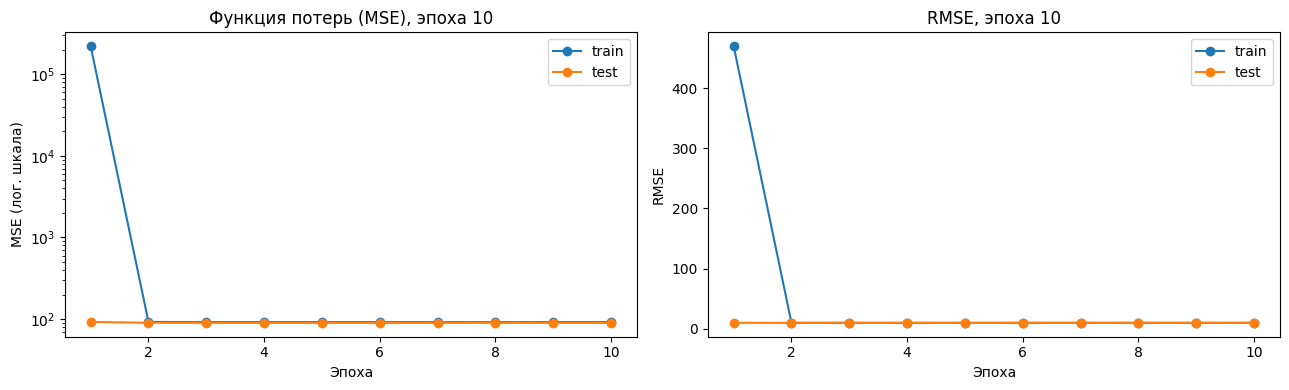

Epoch  1: train_loss=221044.4878, test_loss=92.3468, train_rmse=470.1537, test_rmse=9.6097
Epoch  2: train_loss=92.3784, test_loss=90.2009, train_rmse=9.6114, test_rmse=9.4974
Epoch  3: train_loss=91.8089, test_loss=90.0119, train_rmse=9.5817, test_rmse=9.4875
Epoch  4: train_loss=91.7158, test_loss=89.9068, train_rmse=9.5768, test_rmse=9.4819
Epoch  5: train_loss=91.7340, test_loss=89.8733, train_rmse=9.5778, test_rmse=9.4802
Epoch  6: train_loss=91.7357, test_loss=89.9226, train_rmse=9.5779, test_rmse=9.4828
Epoch  7: train_loss=91.7277, test_loss=89.9469, train_rmse=9.5775, test_rmse=9.4840
Epoch  8: train_loss=91.7255, test_loss=90.1306, train_rmse=9.5773, test_rmse=9.4937
Epoch  9: train_loss=91.7240, test_loss=89.8864, train_rmse=9.5773, test_rmse=9.4808
Epoch 10: train_loss=91.7321, test_loss=89.9230, train_rmse=9.5777, test_rmse=9.4828


In [20]:
LR = 0.001
NUM_EPOCHS = 10

train_losses, test_losses = [], []
train_rmse, test_rmse = [], []
log_lines = []

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = train_epoch(model, LR, train_loader, epoch=epoch)
    test_loss = evaluate(model, test_loader)

    train_rmse_ = train_loss ** 0.5
    test_rmse_ = test_loss  ** 0.5

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_rmse.append(train_rmse_)
    test_rmse.append(test_rmse_)

    log_lines.append(
        f"Epoch {epoch:2d}: train_loss={train_loss:.4f}, "
        f"test_loss={test_loss:.4f}, train_rmse={train_rmse_:.4f}, "
        f"test_rmse={test_rmse_:.4f}"
    )

    clear_output(wait=True)
    plot_training(train_losses, test_losses,
                  train_rmse, test_rmse, epoch)
    print("\n".join(log_lines))

## Часть II. Заводим нейронную сеть (максимум 10 баллов)

Ниже нам предстоит реализовать довольно много различных нейросетей и поставить целую серию экспериментов. Чтобы это всё происходило без боли и страданий, нам нужно держать код в удобном виде.

При решении заданий вы можете придерживаться любой адекватной струкуры кода, но мы советуем воспользоваться сигнатурами функций, которые приведены ниже. При необходимости вы можете добавить в них любые нужные вам аргументы и любой нужный функционал. Более того, хорошей практикой является не делать эти функции слишком громоздкими и выносить разные хитрые штуки в отдельные функции.

In [21]:
!nvidia-smi

Sat Oct 17 17:19:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P0             29W /   70W |     161MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [22]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0))
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

CUDA available: True
Device name: Tesla T4
Device: cuda


воспользуемся немного модернизированными кодами из семинара 1 для этого задания

In [23]:
def training_epoch(model, optimizer, criterion, train_loader):
    """Одна эпоха обучения
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
    """

    # your code here  ♪┏(・o･)┛
    train_loss = 0.0
    model.train() #ркжим обучения

    for x_batch, y_batch in tqdm(train_loader, leave=False):
        x_batch = x_batch.to(device)#перенос на GPU
        y_batch = y_batch.to(device)

        optimizer.zero_grad()#обнуляем градиенты
        y_pred = model(x_batch)  #прямой прозод
        loss = criterion(y_pred, y_batch) #функция потерь
        loss.backward()#обратный проход
        optimizer.step() #шаг оптимизатора

        train_loss += loss.item() * x_batch.shape[0] #суммируем потери

    train_loss /= len(train_loader.dataset)
    return train_loss


    raise NotImplementedError


@torch.no_grad()
def validation_epoch(model, criterion, val_loader):
    """Одна эпоха валидации модели
    params:
        model - torch.nn.Module to be fitted
        criterion - loss function from torch.nn
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
    """

    # your code here   ฅ^•ﻌ•^ฅ
    model.eval()  #режим валидации
    total_loss = 0.0

    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(x_batch)#прямой проход
        loss = criterion(y_pred, y_batch)#функция потерь

        total_loss += loss.item() * x_batch.shape[0]

    return total_loss / len(val_loader.dataset)



@torch.no_grad()
def predict(model, data_loader):
    """ Предсказания модели
    params:
        model - torch.nn.Module to be evaluated on test set
        criterion - loss function from torch.nn
        data_loader - torch.utils.data.Dataloader with test set
    ----------
    returns:
        predicts - torch.tensor with shape (len(test_loader.dataset), ),
                   which contains predictions for test objects
    """

    # your code here  =^･ω･^=
    model.eval() #режим валидации
    predictions = [] #для батчей предсказаний

    for x_batch, _ in data_loader:
        x_batch = x_batch.to(device)
        y_pred = model(x_batch)

        predictions.append(y_pred.cpu()) #переносим на CPU

    predicts = torch.cat(predictions) #все батчи в один тензор
    return predicts


def train(model, optimizer, criterion, train_loader, val_loader, epochs):
    """ Обучение модели
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
        epochs - number of training epochs
    """

    # your code here  ¯\_(ツ)_/¯
    train_losses, val_losses = [], []

    for epoch in range(1, epochs + 1):
        train_loss = training_epoch(model, optimizer, criterion, train_loader) #обучаем на эпохе
        val_loss = validation_epoch(model, criterion, val_loader) #функция потерь

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(f"Epoch {epoch:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")

    return train_losses, val_losses

    raise NotImplementedError

**Задание 2 (2 балла)**

Попробуем обучить нашу первую нейронную сеть. Здесь целевая переменная дискретная &mdash; это год выпуска песни. Поэтому будем учить сеть на классификацию.

- В качестве архитектуры сети возьмите два линейных слоя с активацией ReLU между ними c числом скрытых нейронов, равным 128.
- Используйте SGD с `lr=1e-3`.
- Возьмите размер мини-батча около 32-64, примерно 3-4 эпох обучения должно быть достаточно.
- Также преобразуйте целевую переменную так, чтобы ее значения принимали значения от $0$ до $C-1$, где $C$ &mdash; число классов (лучше передайте преобразованное значение в DataLoader, исходное нам еще пригодится)
- В качестве метрики качества мы используем RMSE. При его подсчёте вам нужно заменить предсказанный нейросеткой класс на конкретный год выпуска песни и использовать его как прогноз.

In [24]:
# your code here (￣ω￣)

Преобразуем цклевую перемернную в классы

In [25]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
#копия
y_train_orig = y_train.copy()
y_val_orig = y_val.copy()
y_test_orig = y_test.copy()
#преобразуем
y_train_с = label_encoder.fit_transform(y_train)
y_val_с = label_encoder.transform(y_val)
y_test_с = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)
print(f"Количество классов (лет): {num_classes}")

Количество классов (лет): 89


Создаем новый DataLoader ( преобразуем функцию из части 1)

In [26]:
def make_loader_с (X_np, y_np, shuffle, batch_size, generator=None, worker_init_fn=None):
    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    y_tensor = torch.tensor(y_np, dtype=torch.long) #изменили для коассификации

    dataset = TensorDataset(X_tensor, y_tensor)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        worker_init_fn=worker_init_fn,
        generator=generator,
    )
    return loader


In [27]:
train_loader_c = make_loader_с(X_train_scaled, y_train_с, shuffle=True, batch_size=64, generator=g, worker_init_fn=seed_worker)
val_loader_с = make_loader_с(X_val_scaled, y_val_с, shuffle=False, batch_size=256)
test_loader_с = make_loader_с(X_test_scaled, y_test_с, shuffle=False, batch_size=256)

Строим модель. Ипользуем код из семинара 1(способ 1)

In [28]:
in_features = X_train.shape[1]

In [29]:
import torch.nn as nn

class SongYearClass(nn.Module):
    def __init__(self, in_features, num_classes):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.model(x)

#модель
model_c = SongYearClass(in_features=X_train_scaled.shape[1], num_classes=num_classes).to(device)

Объявляем оптимизатор и обучаем модель

In [30]:
optimizer = torch.optim.SGD(model_c.parameters(), lr= 1e-3)
criterion = nn.CrossEntropyLoss()

In [31]:
#используем функцию train
train_losses, val_losses = train(
    model=model_c, optimizer=optimizer, criterion=criterion,
    train_loader=train_loader_c, val_loader=val_loader_с, epochs=4
)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=4.0840, val_loss=3.7997


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=3.6630, val_loss=3.5674


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=3.5221, val_loss=3.4833


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  4: train_loss=3.4599, val_loss=3.4379


Считаем RMSE:

In [32]:
model_c.eval()
test_preds_logits = predict(model_c, test_loader_с) #сырые предсказания
predicted_classes = test_preds_logits.argmax(dim=1).cpu().numpy() #класс

predicted_years = label_encoder.inverse_transform(predicted_classes) #классы в год

nn_rmse = np.sqrt(np.mean((y_test_orig - predicted_years) ** 2)) #RMSE

print(f"RMSE нейросети-классификатора на тесте: {nn_rmse:.2f}")

RMSE нейросети-классификатора на тесте: 13.26


**Задание 3 (1 балл).** Прокомментируйте ваши наблюдения. Удалось ли побить бейзлайн? Как вы думаете, хорошая ли идея учить классификатор для этой задачи? Почему?

**Ответ:**
- Наш бейзлайн (Ridge-регрессия) показал RMSE 9.47, а константа (среднее) - 10.85. А наша нейросеть-классификатор показала RMSE ниже двух предыдущих моделей на уровне 13.26. Значит, побить бейзлайн не удалось.
- Я думаю, что это плохая идея, потому что наша целевая переменная это упорядоченная величина. А наша модель не видит разницы между ошибкой предсказания на соседний год и на год сильно раньше/позже настоящего(Например, вместо 2000 прелсказать 2001 равносильно тому, чтобы вместо 2000 предсказать 1980). А также целевая метрика (RMSE) - напрямую учитывает расстояние между годами. Но классификатор максимизирует попадание в год, не учитывая блищость этого предсказания к реальному году.


**Задание 4 (2 балла).** Теперь попробуем решать задачу как регрессию. Обучите нейронную сеть на MSE.

- Используйте такие же гиперпараметры обучения.
- Когда передаете целевую переменную в DataLoader, сделайте reshape в (-1, 1).
- Если что-то пойдет не так, можете попробовать меньшие значения `lr`.

Используем DataLoader ( из части 1)

In [33]:
# your code here ( ⚆ _ ⚆)
train_loader_r = make_loader(X_train_scaled, y_train_orig, shuffle=True, batch_size=64, generator=g, worker_init_fn=seed_worker)
val_loader_r = make_loader(X_val_scaled, y_val_orig, shuffle=False, batch_size=256)
test_loader_r = make_loader(X_test_scaled, y_test_orig, shuffle=False, batch_size=256)

Строим модель

In [34]:
class SongYearReg(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )
    def forward(self, x):
        return self.model(x)

model_reg = SongYearReg(in_features=X_train.shape[1]).to(device)

Объявляем оптимизатор и обучаем модель

In [35]:
optimizer_r = torch.optim.SGD(model_reg.parameters(), lr=1e-4)
criterion_r = nn.MSELoss()

In [36]:
train_losses_r, val_losses_r = train(
    model=model_reg, optimizer=optimizer_r, criterion=criterion_r,
    train_loader=train_loader_r, val_loader=val_loader_r, epochs=4
)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=15576.6634, val_loss=1465.1796


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=2448.1675, val_loss=550.8380


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=654.0610, val_loss=202.1226


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  4: train_loss=586.0528, val_loss=431.0525


Считаем RMSE:

In [37]:
model_reg.eval()
test_preds = predict(model_reg, test_loader_r)

predicted_years = test_preds.cpu().numpy().squeeze()
reg_rmse = np.sqrt(np.mean((y_test_orig - predicted_years) ** 2))

print(f"RMSE нейросети-регрессора на тесте: {reg_rmse:.2f}")

RMSE нейросети-регрессора на тесте: 20.80


**Задание 5 (1 балл).** Получилось ли у вас стабилизировать обучение? Помогли ли меньшие значения `lr`? Стало ли лучше от замены классификации на регрессию? Как вы думаете, почему так происходит? В качестве подсказки можете посмотреть на распределение целевой переменной и магнитуду значений признаков.

**Ответ:**  
Нет, у меня не получилось стабилизировать обучение. Я попоробовала значения lr от 1e-3 до 1e-4, но это ни к чему хорошему не привело. При lr 1e-3 MSE все равны nan, как и RMSE. А при При lr 1e-4 RMSE в два раза хуже бейзлайнов, что говорит о том, что обучение не сходится.

Мне кажется, что замена классификации на регрессию была хорошей идеей, так как регрессия учитывает расстояние между предсказанием и реальным значением(то есть видит разницу ошибки для соседнего года и для более позднего/раннего года). Но сейчас регрессия показывает худшие результаты, поэтому нам необзодимо сначала сделать нормализацию целевой переменной, котрая позволит использовать регрессию. А без нее регрессия делает только хуже.

Так происходит потому что годы выпуска имееют большие значения (1920-2010), а при случайной нейросети предсказания выдают что-то близкое к 0, так как начальные веса модели маленькие. Из-за этого ошибка предсказания MSE становится очень большой. А тогда, поскольку градиентный спуск пропорционален ошибке, то он становится просто огромным. И это приводит к тому, что веса модели за 1 итерацию улетают в inf или nan. Вычисления ломаются.

**Задание 6 (1 балл).** Начнем с того, что попробуем отнормировать целевую переменную. Для этого воспользуемся min-max нормализацией, чтобы целевая переменная принимала значения от 0 до 1. Реализуйте функции `normalize` и `denormalize`, которые, соответственно, нормируют целевую переменную и применяют обратное преобразование. Минимум и максимум оцените по обучающей выборке (то есть эти константы должны быть фиксированными и не зависеть от передаваемой выборки).

In [38]:
y_min = y_train_orig.min()
y_max = y_train_orig.max()


In [39]:
def normalize(sample):
    """
    Min-max normalization to convert sample to [0, 1] range
    """
    # your code here ᕦ(ò_óˇ)ᕤ
    res = (sample - y_min)/(y_max - y_min)
    return (res)

def denormalize(sample):
    """
    Denormalize sample from [0, 1] to initial range
    """
    # your code here ( ⚆ ω ⚆)
    res = sample * (y_max - y_min) + y_min
    return (res)

**Задание 7 (1 балл)** Теперь повторите эксперимент из **задания 4**, обучаясь на нормированной целевой переменной. Сделаем также еще одно изменение: добавим сигмоидную активацию после последнего линейного слоя сети. Таким образом мы гарантируем, что нейронная сеть предсказывает числа из промежутка $[0, 1]$. Использование активации - довольно распространенный прием, когда мы хотим получить числа из определенного диапазона значений.

In [40]:
# your code here  ლ(ಠ益ಠლ)

In [41]:
y_train_norm = normalize(y_train_orig)
y_val_norm   = normalize(y_val_orig)
y_test_norm  = normalize(y_test_orig)

Используем DataLoader ( из части 1) уже для нрормированного таргета

In [42]:
train_loader_rn = make_loader(X_train_scaled, y_train_norm, shuffle=True, batch_size=64, generator=g, worker_init_fn=seed_worker)
val_loader_rn = make_loader(X_val_scaled,   y_val_norm,   shuffle=False, batch_size=256)
test_loader_rn = make_loader(X_test_scaled,  y_test_norm,  shuffle=False, batch_size=256)

Строим модель( с Sigmoid на выходе )

In [43]:
class SongYearRegNorm(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid(), #выход в [0, 1]
        )
    def forward(self, x):
        return self.model(x)

model_regn = SongYearRegNorm(in_features=X_train.shape[1]).to(device)

Объявляем оптимизатор и обучаем модель

In [44]:
optimizer_regn = torch.optim.SGD(model_regn.parameters(), lr=1e-3)
criterion_regn = nn.MSELoss()

In [45]:
train_losses_reg7, val_losses_reg7 = train(
    model=model_regn, optimizer=optimizer_regn, criterion=criterion_regn,
    train_loader=train_loader_rn, val_loader=val_loader_rn, epochs=4,
)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0422, val_loss=0.0204


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0179, val_loss=0.0168


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0161, val_loss=0.0160


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  4: train_loss=0.0155, val_loss=0.0155


Считаем RMSE:

In [46]:
model_regn.eval()
test_preds_norm = predict(model_regn, test_loader_rn).squeeze(-1).numpy()

test_preds_years = denormalize(test_preds_norm) #обратно в год
rmse_regn = np.sqrt(np.mean((y_test_orig - test_preds_years) ** 2))

print(f"RMSE нейросети-регрессии на тесте (нормированный): {rmse_regn:.2f}")


RMSE нейросети-регрессии на тесте (нормированный): 10.86


**Задание 8 (2 балла).** На этот раз попробуем отнормировать не только целевую переменную, но и сами данные, которые подаются сети на вход. Для них будем использовать нормализацию через среднее и стандартное отклонение. Преобразуйте данные и повторите прошлый эксперимент. Скорее всего, имеет смысл увеличить число эпох обучения.

In [47]:
from sklearn.preprocessing import StandardScaler

 # your code here  ( ͡° ͜ʖ ͡°)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

уже до этого использовали нормированные данные)

Cоздадим новые DataLoader (для чистоты):

In [48]:
train_loader_rn8 = make_loader(X_train_scaled, y_train_norm, shuffle=True, batch_size=64, generator=g, worker_init_fn=seed_worker)
val_loader_rn8   = make_loader(X_val_scaled,   y_val_norm,   shuffle=False, batch_size=256)
test_loader_rn8  = make_loader(X_test_scaled,  y_test_norm,  shuffle=False, batch_size=256)

Объявляем оптимизатор и обучаем модель(из задания 7)

In [49]:
set_global_seed(42)

model_regn8 = SongYearRegNorm(in_features=X_train.shape[1]).to(device)

optimizer_regn8 = torch.optim.SGD(model_regn8.parameters(), lr=1e-3)
criterion_regn8 = nn.MSELoss()

In [50]:
train_losses_reg8, val_losses_reg8 = train(
    model=model_regn8, optimizer=optimizer_regn8, criterion=criterion_regn8,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15,
)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0411, val_loss=0.0183


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0163, val_loss=0.0155


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0149, val_loss=0.0149


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0133, val_loss=0.0134


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0132, val_loss=0.0133


Считаем RMSE:

In [51]:
model_regn8.eval()
test_preds_norm8 = predict(model_regn8, test_loader_rn8).squeeze(-1).numpy()

test_preds_years8 = denormalize(test_preds_norm8) #обратно в год
rmse_regn8 = np.sqrt(np.mean((y_test_orig - test_preds_years8) ** 2))

print(f"RMSE нейросети-регрессии на тесте (нормированный): {rmse_regn8:.2f}")


RMSE нейросети-регрессии на тесте (нормированный): 10.10


Если вы все сделали правильно, то у вас должно было получиться качество, сравнимое с `Ridge` регрессией.

**Мораль:** как видите, нам пришлось сделать очень много хитрых телодвижений, чтобы нейронная сеть работала хотя бы так же, как и простая линейная модель. Здесь, конечно, показан совсем экстремальный случай, когда без нормализации данных нейронная сеть просто не учится. Как правило, в реальности завести нейронную сеть из коробки не очень сложно, но вот заставить ее работать на полную &mdash; куда более трудоемкая задача. Написание пайплайнов обучения нейросетевых моделей требует большой аккуратности, а дебаг часто превращается в угадайку. К счастью, очень часто на помощь приходит интуиция, и мы надеемся, что вы сможете выработать ее в течение нашего курса. Начнем с двух советов, которые стоит принять на вооружение:

- Обязательно начинаем любые эксперименты с бейзлайнов: без них мы бы не поняли, что нейронная сеть не учится в принципе.
- При постановке эксперментов старайтесь делать минимальное количество изменений за раз (в идеале одно!): только так можно понять, какие конкретно изменения влияют на результат.

## Часть III. Улучшаем нейронную сеть (максимум 10 баллов)

Продолжим экспериментировать с нейронной сетью, чтобы добиться еще лучшего качества.

**Задание 9 (1 балл).** Давайте попробуем другие оптимизаторы. Обучите нейросеть с помощью SGD+momentum и Adam. Опишите свои наблюдения и в дальнейших запусках используйте лучший оптимизатор. Для Adam обычно берут learning rate поменьше, в районе $10^{-3}$.

In [52]:
set_global_seed(42)
model_sgd_m = SongYearRegNorm(in_features=X_train.shape[1]).to(device)

optimizer_sgd_m = torch.optim.SGD(model_sgd_m.parameters(), lr=1e-3, momentum=0.9)
criterion_sgd_m = nn.MSELoss()

train_losses_sgd_m, val_losses_sgd_m = train(
    model=model_sgd_m, optimizer=optimizer_sgd_m, criterion=criterion_sgd_m,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

model_sgd_m.eval()
test_preds_sgd_m = predict(model_sgd_m, test_loader_rn8).squeeze(-1).numpy()

test_preds_years_sgd_m = denormalize(test_preds_sgd_m)
rmse_sgd_m = np.sqrt(np.mean((y_test_orig - test_preds_years_sgd_m) ** 2))

print(f"RMSE с SGD+momentum на тесте: {rmse_sgd_m:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0172, val_loss=0.0137


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0132, val_loss=0.0130


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0126, val_loss=0.0126


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0109, val_loss=0.0111


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0109, val_loss=0.0110
RMSE с SGD+momentum на тесте: 9.23


In [53]:
# your code here  ( ཀ ʖ̯ ཀ)
set_global_seed(42)
model_adam = SongYearRegNorm(in_features=X_train.shape[1]).to(device)

optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=1e-3)
criterion_adam = nn.MSELoss()

train_losses_adam, val_losses_adam = train(
    model=model_adam, optimizer=optimizer_adam, criterion=criterion_adam,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

model_adam.eval()
test_preds_adam = predict(model_adam, test_loader_rn8).squeeze(-1).numpy()

test_preds_years_adam = denormalize(test_preds_adam)
rmse_adam = np.sqrt(np.mean((y_test_orig - test_preds_years_adam) ** 2))

print(f"RMSE с оптимизатором Adam на тесте: {rmse_adam:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0113, val_loss=0.0104


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0100, val_loss=0.0100


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0098, val_loss=0.0100


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0092, val_loss=0.0098


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0091, val_loss=0.0098
RMSE с оптимизатором Adam на тесте: 8.83


Наблюдения:
SGD с моментумом (lr=1e-3) делает стабильное и достаточно плавное обучение. Он постепенно снижает функцию потерь в каждой эпохе. А Adam (lr=1e-3) сходится быстрее, к концу 1 эпохи уже имеет значительное преимущество, так как сходится "агрессивно" на первых эпохах. Итоговое значение RMSE на SGD с моментумом (lr=1e-3) равно 9.23, тогда как RMSE на Adam (lr=1e-3) - 8.83. Это достатоно весомый разрыв.

**Вывод:** В качествее лучшего оптимищатора для для дальнейших экспериментов мы выбираем **Adam**, так как он обеспечивает более быструю сходимость.

**Задание 10 (1 балл).** Теперь сделаем нашу нейронную сеть более сложной. Попробуйте сделать сеть:

- более широкой (то есть увеличить размерность скрытого слоя, например, вдвое)
- более глубокой (то есть добавить еще один скрытый слой)

In [54]:
# your code here  (๑-﹏-๑)
class SongYearRegNormWide(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 256), #широкая
            nn.ReLU(),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.model(x)

class SongYearRegNormDeep(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 128), #глубокая
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.model(x)


Широкая модель

In [55]:
set_global_seed(42)
model_wide = SongYearRegNormWide(in_features=X_train.shape[1]).to(device)

optimizer_wide = torch.optim.Adam(model_wide.parameters(), lr=1e-3)
criterion_wide = nn.MSELoss()

train_losses_wide, val_losses_wide = train(
    model=model_wide, optimizer=optimizer_wide, criterion=criterion_wide,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

model_wide.eval()
test_preds_wide = predict(model_wide, test_loader_rn8).squeeze(-1).numpy()

test_preds_years_wide = denormalize(test_preds_wide)
rmse_wide = np.sqrt(np.mean((y_test_orig - test_preds_years_wide) ** 2))

params_wide = sum(p.numel() for p in model_wide.parameters())
print(f"Wide (256): RMSE = {rmse_wide:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0110, val_loss=0.0102


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0100, val_loss=0.0100


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0098, val_loss=0.0099


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0089, val_loss=0.0100


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0088, val_loss=0.0100
Wide (256): RMSE = 8.96


Глубокая модель

In [56]:
set_global_seed(42)
model_deep = SongYearRegNormDeep(in_features=X_train.shape[1]).to(device)

optimizer_deep = torch.optim.Adam(model_deep.parameters(), lr=1e-3)
criterion_deep = nn.MSELoss()

train_losses_deep, val_losses_deep = train(
    model=model_deep, optimizer=optimizer_deep, criterion=criterion_deep,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

model_deep.eval()
test_preds_deep = predict(model_deep, test_loader_rn8).squeeze(-1).numpy()
test_preds_years_deep = denormalize(test_preds_deep)
rmse_deep = np.sqrt(np.mean((y_test_orig - test_preds_years_deep) ** 2))

print(f"Deep (128-128): RMSE = {rmse_deep:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0107, val_loss=0.0101


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0098, val_loss=0.0099


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0095, val_loss=0.0098


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0080, val_loss=0.0099


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0079, val_loss=0.0098
Deep (128-128): RMSE = 8.95


Опишите, как увеличение числа параметров модели влияет на качество на обучающей и валидационной выборках (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

С увеличением числа параметров train_loss уменьшается: ошибка на обучении закономерно снижается всё больше. У простой модели финальный train_loss падает до 0.0091, то у широкой - до 0.0088, а у глубокой - до 0.0079.

С увеличением числа параметров val_loss не изменяется. Разницы между моделями практически нет, так как все три финальных val_loss  около 0.0098–0.0099. Также  у широкой модели наблюдается увеличение val_loss после 4,6,9,10 эпох, как и у глубокой модели после 6,9,12,13 эпохи.

С увеличением числа параметров RMSE на тесте растёт: усложнение моделей ухудшило результат.  У простой модели-  8.83, у широкой - 8.96, у глубокой - 8.95.

**Вывод:** Все это говорит нам о том, что широкая и глубокая модели переобучились. Модели лучше запоминают train, но теряют способность обобщать, так как полстраиваются под данные. Сильнее переобучилась Deep-модель.



**Задание 11 (1 балл).** Как вы должны были заметить, более сложная модель стала сильнее переобучаться. Попробуем разные методы регуляризации, чтобы бороться с переобучением. Проведите два эксперимента:

- Добавьте слой дропаута с параметром $p=0.2$ после каждого линейного слоя, кроме последнего.
- Попробуйте batch-нормализацию вместо дропаута. Строго говоря, batch-нормализация не является методом регуляризации, но никто не запрещает нам экспериментировать с ней.

Dropout

In [57]:
#модель
class SongYearRegNormDeepDropout(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.model(x)

#обучение
set_global_seed(42)
model_dropout = SongYearRegNormDeepDropout(in_features=X_train.shape[1]).to(device)

optimizer_dropout = torch.optim.Adam(model_dropout.parameters(), lr=1e-3)
criterion_dropout = nn.MSELoss()

train_losses_dropout, val_losses_dropout = train(
    model=model_dropout, optimizer=optimizer_dropout, criterion=criterion_dropout,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

#RMSE
model_dropout.eval()
test_preds_dropout = predict(model_dropout, test_loader_rn8).squeeze(-1).numpy()
test_preds_years_dropout = denormalize(test_preds_dropout)
rmse_dropout = np.sqrt(np.mean((y_test_orig - test_preds_years_dropout) ** 2))

print(f"Dropout: RMSE = {rmse_dropout:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0112, val_loss=0.0102


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0102, val_loss=0.0102


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0101, val_loss=0.0099


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0094, val_loss=0.0096


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0093, val_loss=0.0096
Dropout: RMSE = 8.70


Batch Normalization

In [58]:
#модель
class SongYearRegNormDeepBN(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.model(x)

#обучение
set_global_seed(42)
model_bn = SongYearRegNormDeepBN(in_features=X_train.shape[1]).to(device)

optimizer_bn = torch.optim.Adam(model_bn.parameters(), lr=1e-3)
criterion_bn = nn.MSELoss()

train_losses_bn, val_losses_bn = train(
    model=model_bn, optimizer=optimizer_bn, criterion=criterion_bn,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8, epochs=15
)

#RMSE
model_bn.eval()
test_preds_bn = predict(model_bn, test_loader_rn8).squeeze(-1).numpy()
test_preds_years_bn = denormalize(test_preds_bn)
rmse_bn = np.sqrt(np.mean((y_test_orig - test_preds_years_bn) ** 2))

print(f"Batch Normalization: RMSE = {rmse_bn:.2f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0111, val_loss=0.0101


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0099, val_loss=0.0099


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  3: train_loss=0.0097, val_loss=0.0097


... (20 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0086, val_loss=0.0096


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0085, val_loss=0.0095
Batch Normalization: RMSE = 8.79


Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

 **Dropout :**
 train_loss плавно убывает с 0.0112 до 0.0093. А val_loss снижается с 0.0102 до 0.0096. На всех эпохах val_loss не растет, поэтому можно сказать, что переобучение отсутствует. Кроме того, разрыв между train_loss и val_loss небольшой.

Итоговый RMSE на тесте: 8.70, что лучше среди всех ранее рассмотренных моделей.

**Batch Normalization**
train_loss плавно убывает с 0.0111 до 0.0085. А val_loss снижается с 0.0101 до 0.0095. Однако, мы все еще видим небольщую разницу между train и val, что говорит о том, что модель еще чуть-чуть переобучается, но значительно меньше, чем бещ регуляризации.

Итоговый RMSE на тесте: 8.79, что лучше, чем у моделей из задания 10,
но чуть хуже, чем у Dropout.

**Выводы:**
Обе техники помогли снизить переобучение. Но для нас Dropout оказался эффективнее BatchNorm.

**Задание 12 (1 балл).** Теперь, когда мы определились с выбором архитектуры нейронной сети, пора заняться рутиной DL-инженера &mdash; перебором гиперпараметров. Подберите оптимальное значение lr по значению RMSE на валидации (по логарифмической сетке, достаточно посмотреть 3-4 значения). Затем подберите оптимальное значение weight decay для данного lr (тоже по логарифмической сетке, типичные значения этого параметра лежат в диапазоне $[10^{-6}, 10^{-3}]$, но не забудьте включить нулевое значение в сетку). Постройте графики зависимости RMSE на трейне и на валидации от значений параметров. Прокомментируйте получившиеся зависимости.

Берем лучшую архитектуру - Deep Dropout (задание 11)

In [1]:
#в начале подбора lr
g_lr = torch.Generator(); g_lr.manual_seed(42)
train_loader_lr = make_loader(X_train_scaled, y_train_norm, shuffle=True,
                              batch_size=64, generator=g_lr, worker_init_fn=seed_worker)

#в начале подбора wd
g_wd = torch.Generator(); g_wd.manual_seed(42)
train_loader_wd = make_loader(X_train_scaled, y_train_norm, shuffle=True,
                              batch_size=64, generator=g_wd, worker_init_fn=seed_worker)

NameError: name 'torch' is not defined

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import torch

#сетка для lr
lr_grid = [1e-4, 3e-4, 1e-3, 3e-3]
#списки
train_rmse_by_lr = []
val_rmse_by_lr = []

best_lr = None
best_val_rmse_lr = float('inf')

#лоадер без перемешивания
train_loader_eval = make_loader(
    X_train_scaled, y_train_norm, shuffle=False, batch_size=256
)

for lr in lr_grid:
  print(f'Обучение с lr = {lr}')

  #модель
  g = set_global_seed(42)
  train_loader_rn8 = make_loader(X_train_scaled, y_train_norm, shuffle=True, batch_size=64,
                                 generator=g, worker_init_fn=seed_worker)

  model = SongYearRegNormDeepDropout(in_features=X_train.shape[1]).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  criterion = nn.MSELoss()

  train_losses, val_losses = train(
      model=model,
      optimizer=optimizer,
      criterion=criterion,
      train_loader=train_loader_rn8,
      val_loader=val_loader_rn8,
      epochs=15,
  )

  #RMSE
  model.eval()
  #валидация
  val_preds = predict(model, val_loader_rn8).squeeze(-1).numpy()
  val_preds_years = denormalize(val_preds)
  val_rmse = np.sqrt(np.mean((y_val_orig - val_preds_years) ** 2))
  #трейн
  train_preds = predict(model, train_loader_eval).squeeze(-1).numpy()
  train_preds_years = denormalize(train_preds)
  train_rmse = np.sqrt(np.mean((y_train_orig - train_preds_years) ** 2))

  print(f"lr={lr:.0e}: train RMSE={train_rmse:.3f}, val RMSE={val_rmse:.3f}")

  train_rmse_by_lr.append(train_rmse)
  val_rmse_by_lr.append(val_rmse)

  if val_rmse < best_val_rmse_lr:
    best_val_rmse_lr = val_rmse
    best_lr = lr

print(
    f'Оптимальный lr: {best_lr}, val RMSE = {best_val_rmse_lr:.2f}'
)

Обучение с lr = 0.0001


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0144, val_loss=0.0110


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0109, val_loss=0.0105


  0%|          | 0/4530 [00:00<?, ?it/s]

... (111 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0098, val_loss=0.0099


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0098, val_loss=0.0097
lr=3e-03: train RMSE=8.500, val RMSE=8.777
Оптимальный lr: 0.0003, val RMSE = 8.67


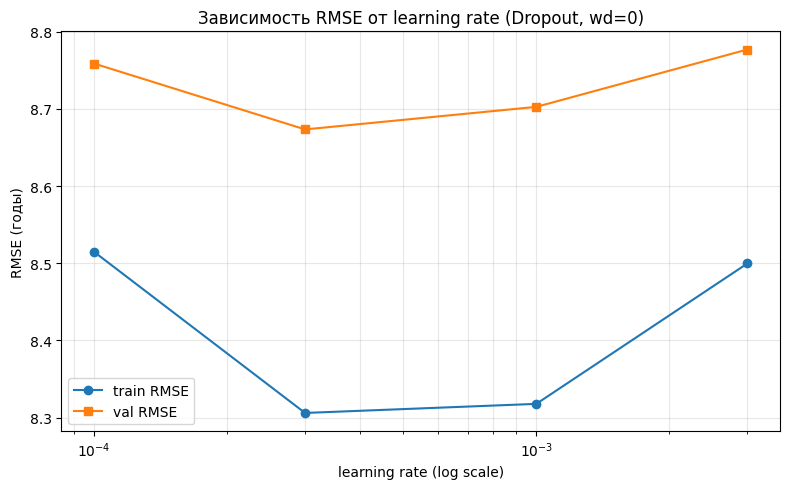

In [60]:
plt.figure(figsize=(8, 5))
plt.plot(lr_grid, train_rmse_by_lr, marker='o', label='train RMSE')
plt.plot(lr_grid, val_rmse_by_lr,   marker='s', label='val RMSE')
plt.xscale('log')
plt.xlabel('learning rate (log scale)')
plt.ylabel('RMSE (годы)')
plt.title('Зависимость RMSE от learning rate (Dropout, wd=0)')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Подбор оптимального weight_decay для найденного lr

In [61]:
#сетка для weight_decay
wd_grid = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]

train_rmse_by_wd = []
val_rmse_by_wd = []

best_wd = None
best_val_rmse_wd = float('inf')

for wd in wd_grid:
  print(f'Обучение с weight_decay = {wd} (при lr = {best_lr})')

  #модель
  g = set_global_seed(42)
  train_loader_rn8 = make_loader(X_train_scaled, y_train_norm, shuffle=True, batch_size=64,
                                 generator=g, worker_init_fn=seed_worker)

  model = SongYearRegNormDeepDropout(in_features=X_train.shape[1]).to(device)
  #weight_decay в оптимизатор Adam
  optimizer = torch.optim.Adam(
      model.parameters(), lr=best_lr, weight_decay=wd
  )
  criterion = nn.MSELoss()

  train_losses, val_losses = train(
      model=model,
      optimizer=optimizer,
      criterion=criterion,
      train_loader=train_loader_rn8,
      val_loader=val_loader_rn8,
      epochs=15,
  )

  #RMSE
  model.eval()
  #валидация
  val_preds = predict(model, val_loader_rn8).squeeze(-1).numpy()
  val_preds_years = denormalize(val_preds)
  val_rmse = np.sqrt(np.mean((y_val_orig - val_preds_years) ** 2))

  #трейн
  train_preds = predict(model, train_loader_eval).squeeze(-1).numpy()
  train_preds_years = denormalize(train_preds)
  train_rmse = np.sqrt(np.mean((y_train_orig - train_preds_years) ** 2))

  print(f"wd={wd:.0e}: train RMSE={train_rmse:.3f}, val RMSE={val_rmse:.3f}")

  train_rmse_by_wd.append(train_rmse)
  val_rmse_by_wd.append(val_rmse)

  if val_rmse < best_val_rmse_wd:
    best_val_rmse_wd = val_rmse
    best_wd = wd

print( f'Оптимальный weight_decay: {best_wd}, , val RMSE: {best_val_rmse_wd:.3f}')

Обучение с weight_decay = 0.0 (при lr = 0.0003)


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  1: train_loss=0.0121, val_loss=0.0104


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch  2: train_loss=0.0104, val_loss=0.0101


  0%|          | 0/4530 [00:00<?, ?it/s]

... (141 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 14: train_loss=0.0107, val_loss=0.0107


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 15: train_loss=0.0107, val_loss=0.0107
wd=1e-03: train RMSE=9.134, val RMSE=9.194
Оптимальный weight_decay: 1e-06, , val RMSE: 8.689


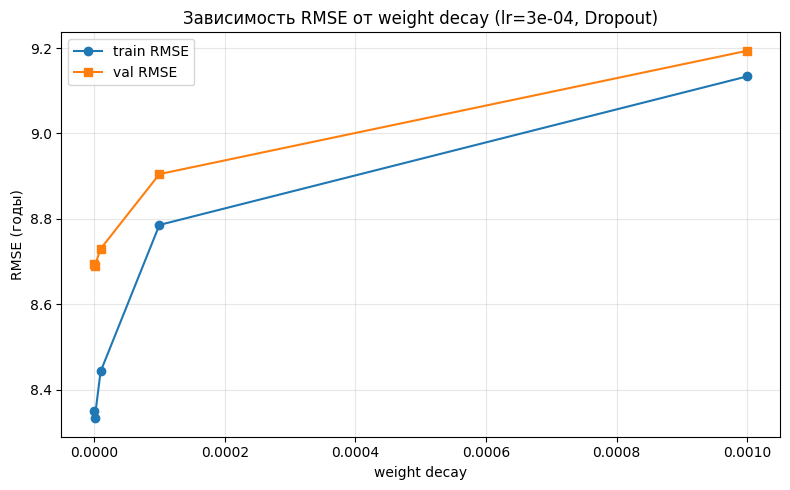

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(wd_grid, train_rmse_by_wd, marker='o', label='train RMSE')
plt.plot(wd_grid, val_rmse_by_wd,   marker='s', label='val RMSE')
plt.xlabel('weight decay')
plt.ylabel('RMSE (годы)')
plt.title(f'Зависимость RMSE от weight decay (lr={best_lr:.0e}, Dropout)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

> Как вы могли заметить, еще одна рутина DL-инженера &mdash; утомительное ожидание обучения моделей.




**Описание результатов экспериментов:**

val RMSE минимальный при lr=3e-4 равен 8.673. При меньших значениях lr(1e-4) модель недообучается, так как val RMSE больше, поэтому обучение не успевает сойтись, однако и при больших значениях lr (1e-3, 3e-3) не достигает минимума, так как перескакивает его, шаг оптимизатора оказался слишком большим, поэтому val RMSE хуже. Это и видно на графике: оранжевая кривая (как и синяя) имеет U-образную форму, с минимумом в точке lr=1e-3 с вершиной (то есть точкой минимума) в lr=1e-3.  Также, при lr=1e-3 умеренный разрыв  между train и val, что говорит о достаточно хорошем обобщении.

Зависимость RMSE от Weight Decay при lr=3e-4 ведет себя монотонно возрастающе. То есть качество модели ухудшается(увеличивается) при увеличении weight decay. И минимальный val RMSE = 8.689 при Weight Decay = 1e-6. Стоит отметить, что при Weight Decay = 0 и Weight Decay = 1e-6 результаты очень схожи. При больших значениях Weight Decay модель недообучается, так как train loss и val loss растут.

Итог: лучшая конфигурация — **lr=3e-4, weight_decay=1e-6**.
Так как Dropout и L2-регуляризация решают одну и ту же
задачу (ограничение емкости модели), то если их использовать вместе, то эффекты складываются, что приводит к
избыточной регуляризации. Поэтому модель становится хуже при увеличении Weight Decay.

**Задание 13 (6 баллов).**

Думаю направление размышлений вы поняли. Постарайтесь с помощью своих экспериментов выбить максимально возможное значение RMSE на тестовой выборке. Соотношение между полученным значением метрики на тестовой выборке и баллами за задание следующее:

- $\text{RMSE} \le 8.90 $ &mdash; 2 балла
- $\text{RMSE} \le 8.80 $ &mdash; 4 балла
- $\text{RMSE} \le 8.75 $ &mdash; 6 баллов

**Различные трюки, которые можно попробовать:**

1. Попробуйте делать во время обучения раннюю остановку обучения и сохранять модель в тот момент, когда качество на валидации начало ухудшаься, то есть модель начала переобучаться
2. Попробуйте усложнить архитектуру нейросет
    - Больше/меньше нейронов
    - Больше/меньше слоёв
    - Другие функции активации (tanh, relu, leaky relu, elu etc)
    - Регуляризация (dropout, l1,l2)
3. Попробуйте другие оптимизаторы, а также смену скорости обучения по расписанию.

И это далеко не полный список. Обратите внимание, что делать grid_search для больших сеток это довольно времязатратное занятие... Попробовать несколько значений, как мы делали в заданиях выше, адекватно, но делать какой-то огромный перебор будет самоубийством.

Логгируйте свои эксперименты. За один прогон пробуйте одно изменение. Иначе будет непонятно какие именно изменения улучшили качество, а какие ухудшили.

Возьмем нашу лучшую модель из задания 12. Но параметр Weight Decay возьмем равным 0. Наши итоговые значения, котрые попытаемся сейчас улучшить: val RMSE = 8,673 train RMSE = 8,306

In [63]:
# your code here
# ༼ つ ಥ_ಥ ༽つ

In [64]:
import copy

def train_early_stopping(model, optimizer, criterion, train_loader, val_loader,
                         max_epochs=30, patience=4, min_delta=1e-5):
  train_losses, val_losses = [], []

  best_val_loss = float('inf')
  best_epoch = 0
  best_state = None
  epochs_without_improvement = 0

  for epoch in range(1, max_epochs + 1):
    train_loss = training_epoch(model, optimizer, criterion, train_loader)
    val_loss = validation_epoch(model, criterion, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch}: train_loss={train_loss:.5f}, val_loss={val_loss:.5f}")

    #улучшение
    if val_loss < best_val_loss - min_delta:
      best_val_loss = val_loss
      best_epoch = epoch
      best_state = copy.deepcopy(model.state_dict())#копия
      epochs_without_improvement = 0
    else:
      epochs_without_improvement += 1
      if epochs_without_improvement >= patience:
        print(f"Ранняя остановка на эпохе {epoch}, лучшая эпоха: {best_epoch}")
        break

  model.load_state_dict(best_state)  #возвращаем лучшие веса
  return train_losses, val_losses, best_epoch

In [65]:
set_global_seed(42)
model_es = SongYearRegNormDeepDropout(in_features=X_train.shape[1]).to(device)
optimizer_es = torch.optim.Adam(model_es.parameters(), lr=3e-4)
criterion_es = nn.MSELoss()

train_losses_es, val_losses_es, best_epoch_es = train_early_stopping(
    model=model_es, optimizer=optimizer_es, criterion=criterion_es,
    train_loader=train_loader_rn8, val_loader=val_loader_rn8,
    max_epochs=30, patience=5
)

#RMSE
model_es.eval()
val_preds_years_es = denormalize(predict(model_es, val_loader_rn8).squeeze(-1).numpy())
val_rmse_es = np.sqrt(np.mean((y_val_orig - val_preds_years_es) ** 2))

test_preds_years_es = denormalize(predict(model_es, test_loader_rn8).squeeze(-1).numpy())
test_rmse_es = np.sqrt(np.mean((y_test_orig - test_preds_years_es) ** 2))

print(f"Лучшая эпоха: {best_epoch_es}")
print(f"Early stopping: val RMSE = {val_rmse_es:.3f}, test RMSE = {test_rmse_es:.3f}")

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 1: train_loss=0.01211, val_loss=0.01040


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 2: train_loss=0.01038, val_loss=0.01006


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 3: train_loss=0.01010, val_loss=0.00993


... (50 outputs left out)

  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 29: train_loss=0.00878, val_loss=0.00945


  0%|          | 0/4530 [00:00<?, ?it/s]

Epoch 30: train_loss=0.00877, val_loss=0.00941
Ранняя остановка на эпохе 30, лучшая эпоха: 25
Лучшая эпоха: 25
Early stopping: val RMSE = 8.635, test RMSE = 8.688


Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

## Бонус (0.1 балла)

Прикрепите фотографию того, как вы начали этот сентябрь. Какую самую классную эмоцию вы испытали за прошедший месяц?

__место для картики и эмоции__
